<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 4: Game Playing — Minimax with Alpha–Beta Pruning</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.2 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Implement an unbeatable Tic-Tac-Toe player using Minimax and Alpha–Beta pruning, and measure how many nodes pruning saves.</div>

## 📘 Theory

In a two-player zero-sum game, **Minimax** backs up utilities: MAX takes the maximum and MIN the minimum of child values.
**Alpha–Beta** keeps $\alpha$ (best value for MAX) and $\beta$ (best value for MIN) and prunes a subtree as soon as $\alpha\ge\beta$. It returns exactly the same decision as Minimax; with perfect ordering, time drops from $O(b^m)$ to $O(b^{m/2})$.

## 🧭 Algorithm

1. If the state is terminal, return its utility (+1 X wins, −1 O wins, 0 draw).
2. MAX node: for each move, v = max(v, MIN-VALUE(child, α, β)); if v ≥ β prune; α = max(α, v).
3. MIN node: for each move, v = min(v, MAX-VALUE(child, α, β)); if v ≤ α prune; β = min(β, v).
4. At the root choose the move with the best backed-up value.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

In [2]:
import math
LINES = [(0,1,2),(3,4,5),(6,7,8),(0,3,6),(1,4,7),(2,5,8),(0,4,8),(2,4,6)]
def winner(b):
    for i, j, k in LINES:
        if b[i] != " " and b[i] == b[j] == b[k]: return b[i]
    return "D" if " " not in b else None
def moves(b): return [i for i, v in enumerate(b) if v == " "]
def play(b, i, p): t = list(b); t[i] = p; return "".join(t)
def utility(w): return {"X": 1, "O": -1, "D": 0}[w]

counter = {"n": 0}
def minimax(b, player):
    counter["n"] += 1; w = winner(b)
    if w: return utility(w), None
    best = (-math.inf, None) if player == "X" else (math.inf, None)
    for m in moves(b):
        v, _ = minimax(play(b, m, player), "O" if player == "X" else "X")
        if (player == "X" and v > best[0]) or (player == "O" and v < best[0]): best = (v, m)
    return best

def alphabeta(b, player, a=-math.inf, be=math.inf):
    counter["n"] += 1; w = winner(b)
    if w: return utility(w), None
    best_m = None
    if player == "X":
        v = -math.inf
        for m in moves(b):
            val, _ = alphabeta(play(b, m, "X"), "O", a, be)
            if val > v: v, best_m = val, m
            a = max(a, v)
            if a >= be: break
    else:
        v = math.inf
        for m in moves(b):
            val, _ = alphabeta(play(b, m, "O"), "X", a, be)
            if val < v: v, best_m = val, m
            be = min(be, v)
            if a >= be: break
    return v, best_m

empty = " " * 9
counter["n"] = 0; v1, m1 = minimax(empty, "X"); n1 = counter["n"]
counter["n"] = 0; v2, m2 = alphabeta(empty, "X"); n2 = counter["n"]
print(f"Minimax    : value {v1}, best first move {m1}, nodes = {n1:,}")
print(f"Alpha-Beta : value {v2}, best first move {m2}, nodes = {n2:,}")
print(f"Pruning saved {100*(1-n2/n1):.1f}% of the nodes — same decision, value 0 means perfect play is a draw.")

Minimax    : value 0, best first move 0, nodes = 549,946
Alpha-Beta : value 0, best first move 0, nodes = 18,297
Pruning saved 96.7% of the nodes — same decision, value 0 means perfect play is a draw.


In [3]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(["Minimax", "Alpha–Beta"], [n1, n2], color=[SLATE, GOLD], edgecolor=NAVY)
for i, v in enumerate([n1, n2]): ax.text(i, v, f"{v:,}", ha="center", va="bottom", color=NAVY, weight="bold")
ax.set_ylabel("nodes generated"); ax.set_title("Tic-Tac-Toe from the empty board")
plt.tight_layout(); plt.savefig(f"{FIG}/exp04_nodes.png", dpi=130); plt.show()

### Self-play: two perfect players (animated)

Final board:
 X | X | O
 O | O | X
 X | O | X
Result: Draw


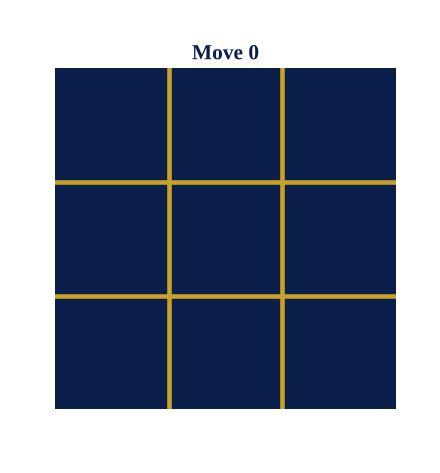

In [4]:
b, p, history = empty, "X", [empty]
while not winner(b):
    _, m = alphabeta(b, p); b = play(b, m, p); history.append(b); p = "O" if p == "X" else "X"
print("Final board:"); [print(" " + " | ".join(b[r*3:r*3+3])) for r in range(3)]
print("Result:", {"D": "Draw", "X": "X wins", "O": "O wins"}[winner(b)])

fig, ax = plt.subplots(figsize=(4, 4.3))
def drawb(k):
    s = history[min(k, len(history) - 1)]; ax.clear(); ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.set_aspect("equal"); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 3, 3, color=NAVY))
    for t in (1, 2): ax.plot([t, t], [0, 3], color=GOLD, lw=3); ax.plot([0, 3], [t, t], color=GOLD, lw=3)
    for i, v in enumerate(s):
        if v != " ": ax.text(i % 3 + .5, 2.5 - i // 3, v, ha="center", va="center", fontsize=40, weight="bold", color="white" if v == "X" else GOLD)
    ax.set_title(f"Move {min(k, len(history)-1)}")
gif = save_gif(animation.FuncAnimation(fig, drawb, frames=len(history) + 2), "exp04_tictactoe_selfplay.gif", fps=1)
display(Image(filename=gif))

## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>Minimax and Alpha–Beta choose the same optimal move and agree that perfect play leads to a draw, but Alpha–Beta generates only a small fraction of the nodes. Self-play between two optimal players ends in a draw.</div>

## 🎤 Viva Questions

1. What are α and β and when is a branch pruned?
2. Does alpha–beta pruning ever change the Minimax decision? Why?
3. How does move ordering affect the effectiveness of pruning?
4. Why is full Minimax infeasible for chess?
5. What is an evaluation function and when is it used?